# 葡萄病害分类训练 | ResNet50 + CBAM

**模型**: ResNet50 + CBAM注意力机制  
**预训练**: 由 cell 2 的 `USE_PRETRAINED` 控制（默认 False = 从零训练）  
**任务**: 四分类  
**输入**: 224×224, ImageNet归一化  

**训练策略 (方案1优化)**:
- 差异化学习率: Backbone 1e-6, Head 1e-4
- 渐进式解冻: 第5轮后解冻所有层
- 增强数据增强: RandomResizedCrop + ColorJitter + 随机平移

**配置**: Batch 32 | 最大100轮 | 早停patience=20

## 1. 导入库与训练配置

In [1]:
DATASET_NAME = 'Grape Disease Dataset'
import copy
import csv
import json
import random
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
import torch
import torch.nn as nn
import torch.optim as optim
from sklearn.metrics import classification_report, confusion_matrix
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
from tqdm.auto import tqdm

plt.rcParams['font.sans-serif'] = ['SimHei', 'DejaVu Sans', 'Arial Unicode MS', 'Microsoft YaHei']
plt.rcParams['axes.unicode_minus'] = False
plt.rcParams['axes.formatter.use_mathtext'] = False

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
BATCH_SIZE = 32
NUM_EPOCHS = 100
# ===== 预训练开关 =====
USE_PRETRAINED = False   # True: ImageNet 权重微调；False: 随机初始化，从零训练
SCRATCH_LR = 1e-3        # 从零训练时的统一学习率（1e-6 是从零训练学不动的）
BACKBONE_LR = 1e-6 if USE_PRETRAINED else SCRATCH_LR
HEAD_LR = 1e-4 if USE_PRETRAINED else SCRATCH_LR
UNFREEZE_EPOCH = 5 if USE_PRETRAINED else None  # 从零训练时所有层一开始就可训练
PATIENCE = 10
NUM_WORKERS = 0
IMG_SIZE = 224

PROJECT_ROOT = Path.cwd()
if PROJECT_ROOT.name.lower() == 'train':
    PROJECT_ROOT = PROJECT_ROOT.parent
DATA_DIR = PROJECT_ROOT / DATASET_NAME
MODEL_DIR = PROJECT_ROOT / 'models'
RUNS_DIR = PROJECT_ROOT / 'train' / 'runs'
MODEL_DIR.mkdir(parents=True, exist_ok=True)
RUNS_DIR.mkdir(parents=True, exist_ok=True)
if not DATA_DIR.is_dir():
    raise FileNotFoundError(f'Dataset directory not found: {DATA_DIR}')
print(f'Dataset: {DATA_DIR.resolve()}')
print(f'Model output: {MODEL_DIR.resolve()}')
print(f'Run output: {RUNS_DIR.resolve()}')
print(f'Device: {DEVICE}')
print(f'预训练权重: {"ImageNet" if USE_PRETRAINED else "随机初始化（从零训练）"}')
print(f'  - Backbone 学习率: {BACKBONE_LR}')
print(f'  - 新层学习率: {HEAD_LR}')
print(f'  - 解冻轮次: {UNFREEZE_EPOCH if USE_PRETRAINED else "不适用（全部层可训练）"}')
print(f'最大训练轮数: {NUM_EPOCHS} | 早停耐心: {PATIENCE}')

Dataset: D:\WorkSpace2\plants-intelligent-system\Grape Disease Dataset
Model output: D:\WorkSpace2\plants-intelligent-system\models
Run output: D:\WorkSpace2\plants-intelligent-system\train\runs
Device: cuda
预训练权重: 随机初始化（从零训练）
  - Backbone 学习率: 0.001
  - 新层学习率: 0.001
  - 解冻轮次: 不适用（全部层可训练）
最大训练轮数: 100 | 早停耐心: 10


## 2. 数据加载与数据增强

## 2.1 数据集初始化

In [2]:
from PIL import Image, ImageFile

IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]
ImageFile.LOAD_TRUNCATED_IMAGES = True

# 🔧 方案1: 增强数据增强，提高泛化能力
train_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE + 32, IMG_SIZE + 32)),  # 先放大
    transforms.RandomResizedCrop(IMG_SIZE, scale=(0.8, 1.0)),  # 随机裁剪
    transforms.RandomHorizontalFlip(p=0.5),  # 恢复50%翻转概率
    transforms.RandomRotation(20),  # 增强到20度旋转
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2, hue=0.1),  # 新增颜色抖动
    transforms.RandomAffine(degrees=0, translate=(0.1, 0.1)),  # 新增平移
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])

eval_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])

split_dirs = {split: DATA_DIR / split for split in ('train', 'val', 'test')}
missing_splits = [split for split, path in split_dirs.items() if not path.is_dir()]
if missing_splits:
    raise FileNotFoundError(f'Missing dataset splits: {missing_splits}')

image_extensions = {'.jpg', '.jpeg', '.png', '.bmp', '.webp'}
invalid_files = []
for split, split_dir in split_dirs.items():
    for image_path in split_dir.rglob('*'):
        if image_path.suffix.lower() in image_extensions:
            try:
                with Image.open(image_path) as image:
                    image.verify()
            except Exception as exc:
                invalid_files.append(f'{split}: {image_path} ({exc})')
if invalid_files:
    raise RuntimeError('发现无法读取的图片，请先修复或删除：\n' + '\n'.join(invalid_files[:10]))

image_datasets = {
    'train': datasets.ImageFolder(split_dirs['train'], train_transform),
    'val': datasets.ImageFolder(split_dirs['val'], eval_transform),
    'test': datasets.ImageFolder(split_dirs['test'], eval_transform),
}
class_names = image_datasets['train'].classes
class_to_idx = image_datasets['train'].class_to_idx
for split, ds in image_datasets.items():
    if ds.class_to_idx != class_to_idx:
        raise ValueError(f'{split} class mapping differs from train: {ds.class_to_idx}')
    if not ds.samples:
        raise ValueError(f'{split} split is empty')

loaders = {
    split: DataLoader(
        ds,
        batch_size=BATCH_SIZE,
        shuffle=(split == 'train'),
        num_workers=NUM_WORKERS,
        pin_memory=(DEVICE.type == 'cuda'),
    )
    for split, ds in image_datasets.items()
}
print('Classes:', class_to_idx)
for split, ds in image_datasets.items():
    print(f'{split}: {len(ds)} images')
print('✓ 数据增强已优化:')
print('  - RandomResizedCrop (scale=0.8-1.0)')
print('  - RandomHorizontalFlip (p=0.5)')
print('  - RandomRotation (20°)')
print('  - ColorJitter (亮度/对比度/饱和度/色调)')
print('  - RandomAffine (平移 ±10%)')

Classes: {'Black Rot': 0, 'ESCA': 1, 'Healthy': 2, 'Leaf Blight': 3}
train: 6213 images
val: 1775 images
test: 887 images
✓ 数据增强已优化:
  - RandomResizedCrop (scale=0.8-1.0)
  - RandomHorizontalFlip (p=0.5)
  - RandomRotation (20°)
  - ColorJitter (亮度/对比度/饱和度/色调)
  - RandomAffine (平移 ±10%)


## 2.2数据集统计

数据集详细统计

【TRAIN】集合:
  Black Rot      : 1640 张 (26.40%)
  ESCA           : 1726 张 (27.78%)
  Healthy        : 1230 张 (19.80%)
  Leaf Blight    : 1617 张 (26.03%)
  总计             : 6213 张

【VAL】集合:
  Black Rot      :  469 张 (26.42%)
  ESCA           :  493 张 (27.77%)
  Healthy        :  351 张 (19.77%)
  Leaf Blight    :  462 张 (26.03%)
  总计             : 1775 张

【TEST】集合:
  Black Rot      :  234 张 (26.38%)
  ESCA           :  246 张 (27.73%)
  Healthy        :  176 张 (19.84%)
  Leaf Blight    :  231 张 (26.04%)
  总计             :  887 张

类别平衡性分析
最大类别样本数: 1726
最小类别样本数: 1230
不平衡比例: 1.40:1
✓ 数据集类别分布相对均衡


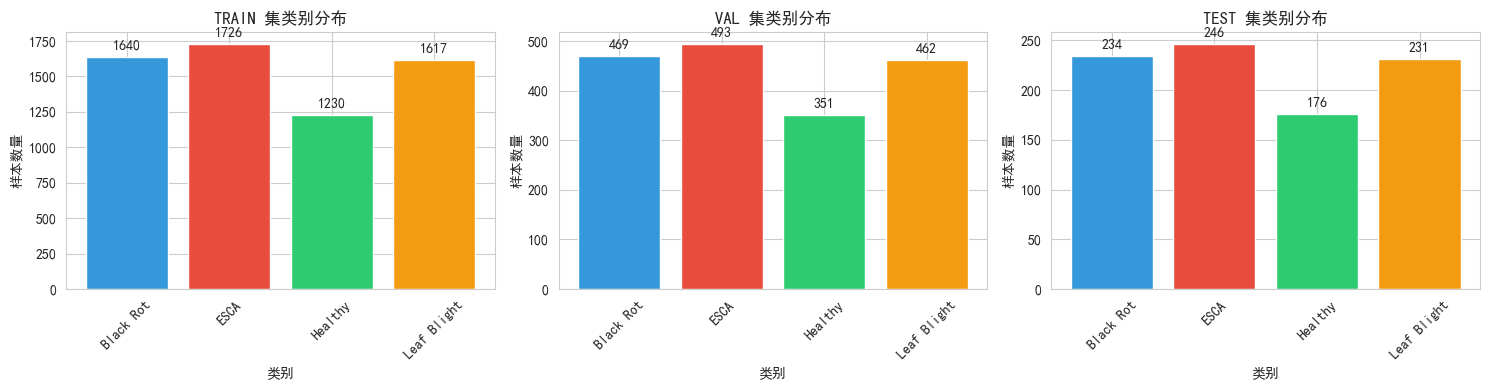

In [3]:
# 数据集统计分析
print("="*60)
print("数据集详细统计")
print("="*60)

for split in ['train', 'val', 'test']:
    print(f"\n【{split.upper()}】集合:")
    targets = image_datasets[split].targets
    for class_name, class_idx in class_to_idx.items():
        count = targets.count(class_idx)
        percentage = count / len(targets) * 100
        print(f"  {class_name:15s}: {count:4d} 张 ({percentage:5.2f}%)")
    print(f"  {'总计':15s}: {len(targets):4d} 张")

# 检查类别平衡性
print("\n" + "="*60)
print("类别平衡性分析")
print("="*60)
train_counts = [image_datasets['train'].targets.count(i) for i in range(len(class_names))]
max_count = max(train_counts)
min_count = min(train_counts)
imbalance_ratio = max_count / min_count
print(f"最大类别样本数: {max_count}")
print(f"最小类别样本数: {min_count}")
print(f"不平衡比例: {imbalance_ratio:.2f}:1")

if imbalance_ratio > 3:
    print("⚠️  数据集存在较严重的类别不平衡！")
else:
    print("✓ 数据集类别分布相对均衡")

# 可视化类别分布
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for idx, split in enumerate(['train', 'val', 'test']):
    targets = image_datasets[split].targets
    class_counts = [targets.count(i) for i in range(len(class_names))]
    axes[idx].bar(class_names, class_counts, color=['#3498db', '#e74c3c', '#2ecc71', '#f39c12'])
    axes[idx].set_title(f'{split.upper()} 集类别分布', fontsize=12, fontweight='bold')
    axes[idx].set_xlabel('类别')
    axes[idx].set_ylabel('样本数量')
    axes[idx].tick_params(axis='x', rotation=45)
    for i, count in enumerate(class_counts):
        axes[idx].text(i, count + max(class_counts)*0.02, str(count),
                      ha='center', va='bottom', fontsize=10)

plt.tight_layout()
plt.show()

## 3. 训练样本展示

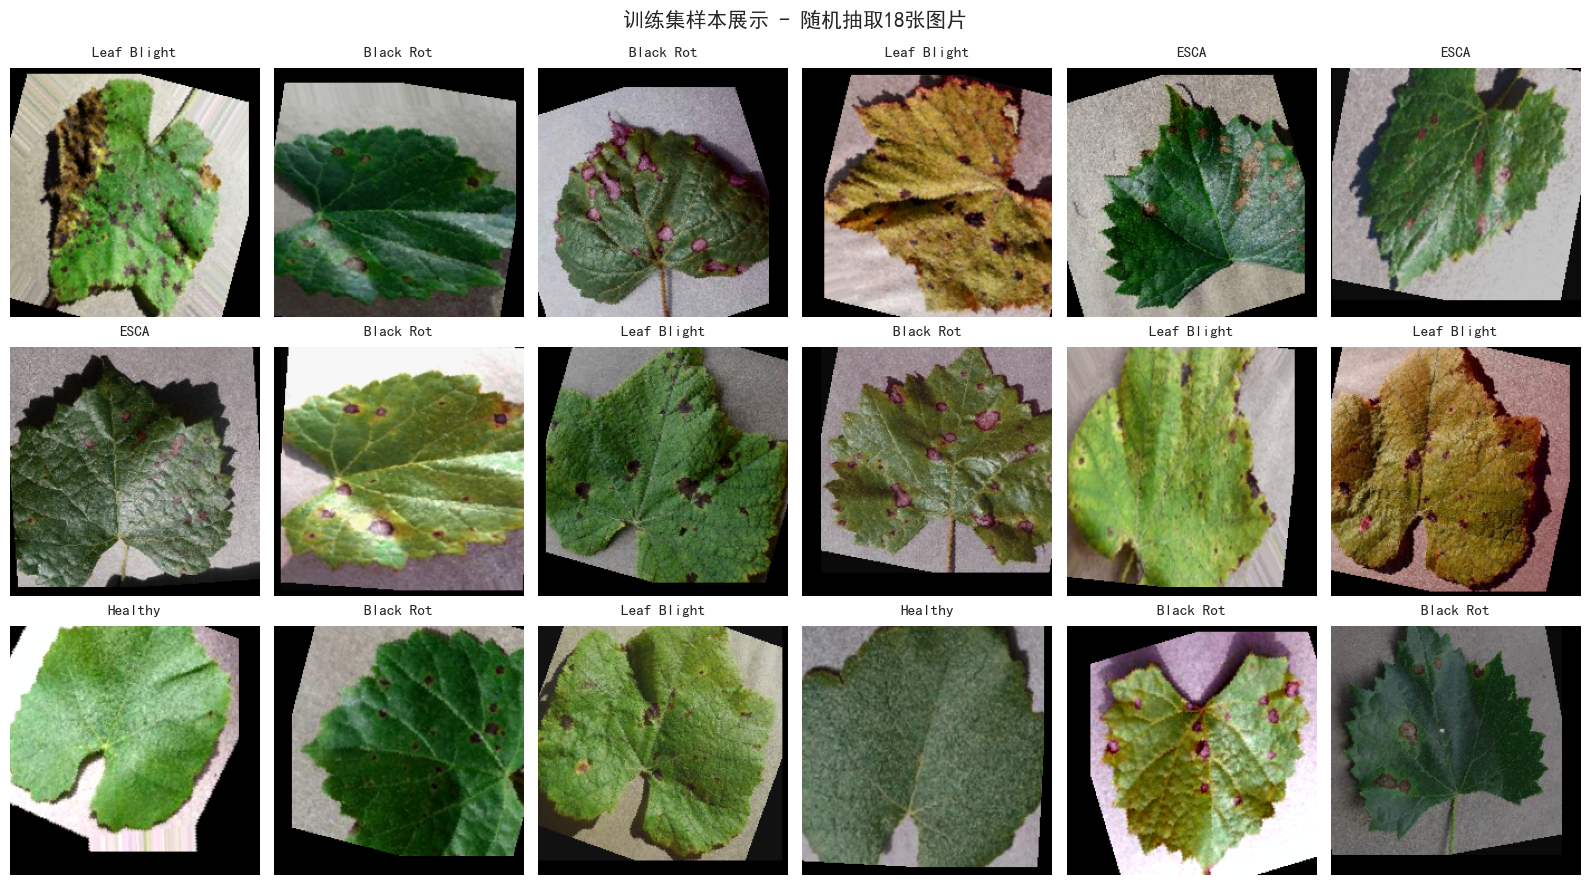

In [4]:
# 展示部分训练样本
fig, axes = plt.subplots(3, 6, figsize=(16, 9))
axes = axes.flatten()
sample_indices = random.sample(range(len(image_datasets['train'])), min(18, len(image_datasets['train'])))

# 用于反归一化的均值和标准差
mean = np.array([0.485, 0.456, 0.406])
std = np.array([0.229, 0.224, 0.225])

for idx, sample_idx in enumerate(sample_indices):
    img, label = image_datasets['train'][sample_idx]
    # 反归一化
    img = img.numpy().transpose((1, 2, 0))
    img = std * img + mean
    img = np.clip(img, 0, 1)
    
    axes[idx].imshow(img)
    axes[idx].set_title(class_names[label], fontsize=11, pad=8)
    axes[idx].axis('off')

plt.suptitle('训练集样本展示 - 随机抽取18张图片', fontsize=15, y=0.99, fontweight='bold')
plt.tight_layout()
plt.show()

## 4. ResNet50 + CBAM 模型

In [5]:
from torchvision.models import resnet50, ResNet50_Weights

class ChannelAttention(nn.Module):
    def __init__(self, in_channels, reduction=16):
        super().__init__()
        self.avg_pool = nn.AdaptiveAvgPool2d(1)
        self.max_pool = nn.AdaptiveMaxPool2d(1)
        self.fc = nn.Sequential(
            nn.Conv2d(in_channels, in_channels // reduction, 1, bias=False),
            nn.ReLU(),
            nn.Conv2d(in_channels // reduction, in_channels, 1, bias=False),
        )
        self.sigmoid = nn.Sigmoid()
    def forward(self, x):
        return self.sigmoid(self.fc(self.avg_pool(x)) + self.fc(self.max_pool(x)))

class SpatialAttention(nn.Module):
    def __init__(self, kernel_size=7):
        super().__init__()
        self.conv = nn.Conv2d(2, 1, kernel_size, padding=kernel_size // 2, bias=False)
        self.sigmoid = nn.Sigmoid()
    def forward(self, x):
        avg_out = torch.mean(x, dim=1, keepdim=True)
        max_out, _ = torch.max(x, dim=1, keepdim=True)
        return self.sigmoid(self.conv(torch.cat([avg_out, max_out], dim=1)))

class CBAM(nn.Module):
    def __init__(self, in_channels, reduction=16):
        super().__init__()
        self.ca = ChannelAttention(in_channels, reduction)
        self.sa = SpatialAttention()
    def forward(self, x):
        x = x * self.ca(x)
        return x * self.sa(x)

class GrapeDiseaseModel(nn.Module):
    def __init__(self, num_classes, use_pretrained=True):
        super().__init__()
        # 使用 ImageNet 预训练权重
        weights = ResNet50_Weights.IMAGENET1K_V1 if use_pretrained else None
        self.backbone = resnet50(weights=weights)
        
        # ResNet50 的 layer4 输出通道数为 2048
        self.cbam = CBAM(2048)
        
        # 替换分类头
        self.backbone.fc = nn.Sequential(
            nn.Dropout(0.5),
            nn.Linear(2048, num_classes)
        )
        
        print(f'✓ 使用 ResNet50 {"+ ImageNet 预训练" if use_pretrained else "(随机初始化)"}')
    
    def forward(self, x):
        b = self.backbone
        x = b.maxpool(b.relu(b.bn1(b.conv1(x))))
        x = b.layer1(x)
        x = b.layer2(x)
        x = b.layer3(x)
        x = b.layer4(x)
        x = self.cbam(x)
        return b.fc(torch.flatten(b.avgpool(x), 1))
    
    # 🔧 方案1: 添加冻结/解冻方法
    def freeze_backbone_early_layers(self):
        """冻结 backbone 的早期层 (conv1, bn1, layer1, layer2)"""
        frozen_count = 0
        for name, param in self.backbone.named_parameters():
            if any(layer in name for layer in ['conv1', 'bn1', 'layer1', 'layer2']):
                param.requires_grad = False
                frozen_count += 1
        print(f'🔒 已冻结 backbone 早期层 ({frozen_count} 个参数)')
    
    def unfreeze_all(self):
        """解冻所有层"""
        for param in self.parameters():
            param.requires_grad = True
        print(f'🔓 已解冻所有层')
    
    def get_parameter_groups(self, backbone_lr, head_lr):
        """返回差异化学习率的参数组"""
        backbone_params = []
        head_params = []
        
        for name, param in self.named_parameters():
            if not param.requires_grad:
                continue
            # CBAM 和 FC 层算作新层，使用较大学习率
            if 'cbam' in name or 'fc' in name:
                head_params.append(param)
            else:
                backbone_params.append(param)
        
        return [
            {'params': backbone_params, 'lr': backbone_lr, 'name': 'backbone'},
            {'params': head_params, 'lr': head_lr, 'name': 'head'}
        ]

model = GrapeDiseaseModel(len(class_names), use_pretrained=USE_PRETRAINED).to(DEVICE)

if USE_PRETRAINED:
    model.freeze_backbone_early_layers()

print(f'总参数量: {sum(p.numel() for p in model.parameters()):,}')
print(f'可训练参数量: {sum(p.numel() for p in model.parameters() if p.requires_grad):,}')
print(f'类别数量: {len(class_names)}')

✓ 使用 ResNet50 (随机初始化)
总参数量: 24,040,614
可训练参数量: 24,040,614
类别数量: 4


## 5. 训练循环（早停与模型保存）

In [6]:
criterion = nn.CrossEntropyLoss()

# 🔧 方案1: 使用差异化学习率
param_groups = model.get_parameter_groups(BACKBONE_LR, HEAD_LR)
optimizer = optim.AdamW(param_groups, weight_decay=1e-4)
scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', factor=0.5, patience=3)

use_amp = DEVICE.type == 'cuda' and hasattr(torch.cuda, 'amp')
scaler = torch.cuda.amp.GradScaler(enabled=use_amp) if use_amp else None

best_val_loss = float('inf')
best_val_acc = 0.0
best_state = None
bad_epochs = 0
history = {'train_loss': [], 'train_acc': [], 'val_loss': [], 'val_acc': [], 'lr_backbone': [], 'lr_head': []}
checkpoint_path = MODEL_DIR / 'grape_disease_best_checkpoint.pth'

print(f'开始训练 - 总共 {NUM_EPOCHS} 轮')
print(f'初始学习率 - Backbone: {BACKBONE_LR}, Head: {HEAD_LR}')
print(f'早停耐心值: {PATIENCE} 轮')
print(f'混合精度训练: {"启用" if use_amp else "关闭"}')
if USE_PRETRAINED:
    print(f'🔧 渐进式训练: 第 {UNFREEZE_EPOCH} 轮后解冻所有层')
else:
    print('🔧 从零训练: 所有层全程可训练')
print('-' * 60)

for epoch in range(NUM_EPOCHS):
    print(f'\n{"=" * 60}')
    print(f'Epoch {epoch + 1}/{NUM_EPOCHS}')
    print(f'{"=" * 60}')
    
    # 🔧 方案1: 在指定轮次解冻所有层并重建优化器
    if USE_PRETRAINED and epoch + 1 == UNFREEZE_EPOCH:
        print(f'\n🔓 触发解冻: 第 {UNFREEZE_EPOCH} 轮，解冻所有层')
        model.unfreeze_all()
        # 重建优化器以包含新解冻的参数
        param_groups = model.get_parameter_groups(BACKBONE_LR, HEAD_LR)
        optimizer = optim.AdamW(param_groups, weight_decay=1e-4)
        scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', factor=0.5, patience=3)
        print(f'✓ 优化器已更新，当前可训练参数: {sum(p.numel() for p in model.parameters() if p.requires_grad):,}\n')
    
    # 记录当前学习率
    current_lr_backbone = optimizer.param_groups[0]['lr']
    current_lr_head = optimizer.param_groups[1]['lr']
    history['lr_backbone'].append(current_lr_backbone)
    history['lr_head'].append(current_lr_head)
    print(f'当前学习率 - Backbone: {current_lr_backbone:.6f}, Head: {current_lr_head:.6f}')

    for phase in ('train', 'val'):
        model.train() if phase == 'train' else model.eval()
        running_loss = 0.0
        running_corrects = 0
        total_samples = 0
        phase_desc = '训练' if phase == 'train' else '验证'

        for inputs, labels in tqdm(loaders[phase], desc=f'{phase_desc}中'):
            inputs = inputs.to(DEVICE, non_blocking=True)
            labels = labels.to(DEVICE, non_blocking=True)
            batch_size = labels.size(0)
            if phase == 'train':
                optimizer.zero_grad(set_to_none=True)

            with torch.set_grad_enabled(phase == 'train'):
                if use_amp:
                    with torch.cuda.amp.autocast():
                        logits = model(inputs)
                        loss = criterion(logits, labels)
                else:
                    logits = model(inputs)
                    loss = criterion(logits, labels)
                preds = logits.argmax(dim=1)

                if phase == 'train':
                    if use_amp:
                        scaler.scale(loss).backward()
                        scaler.unscale_(optimizer)
                        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
                        scaler.step(optimizer)
                        scaler.update()
                    else:
                        loss.backward()
                        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
                        optimizer.step()

            running_loss += loss.item() * batch_size
            running_corrects += (preds == labels).sum().item()
            total_samples += batch_size

        epoch_loss = running_loss / total_samples
        epoch_acc = running_corrects / total_samples
        history[f'{phase}_loss'].append(epoch_loss)
        history[f'{phase}_acc'].append(epoch_acc)
        print(f'{phase_desc}结果 - Loss: {epoch_loss:.4f}, Accuracy: {epoch_acc:.4f} ({running_corrects}/{total_samples})')

        if phase == 'val':
            scheduler.step(epoch_loss)
            if epoch_loss < best_val_loss:
                print(f'✓ 验证损失改善: {best_val_loss:.4f} -> {epoch_loss:.4f}')
                best_val_loss = epoch_loss
                best_val_acc = epoch_acc
                best_state = copy.deepcopy(model.state_dict())
                torch.save({'epoch': epoch + 1, 'model_state_dict': best_state,
                            'optimizer_state_dict': optimizer.state_dict(),
                            'val_loss': best_val_loss, 'val_acc': best_val_acc}, checkpoint_path)
                bad_epochs = 0
                print(f'✓ 已保存最佳模型检查点: {checkpoint_path}')
            else:
                bad_epochs += 1
                print(f'✗ 验证损失未改善 ({bad_epochs}/{PATIENCE})')

    if bad_epochs >= PATIENCE:
        print(f'\n早停触发！验证损失连续 {PATIENCE} 轮未改善')
        print(f'最佳验证损失: {best_val_loss:.4f}, 最佳验证准确率: {best_val_acc:.4f}')
        break

print('\n' + '=' * 60)
print('训练完成！')
print('=' * 60)

if best_state is None:
    raise RuntimeError('训练过程中未产生有效的验证检查点')

checkpoint = torch.load(checkpoint_path, map_location=DEVICE)
model.load_state_dict(checkpoint['model_state_dict'])
print(f'\n已加载最佳模型 (Epoch {checkpoint["epoch"]})')
print(f'最佳验证损失: {checkpoint["val_loss"]:.4f}')
print(f'最佳验证准确率: {checkpoint["val_acc"]:.4f}')

FINAL_MODEL = MODEL_DIR / 'grape_disease_model.pth'
torch.save(model.state_dict(), FINAL_MODEL)
print(f'\n最终模型已保存至: {FINAL_MODEL}')

history_path = RUNS_DIR / 'grape_disease_training_history.csv'
with history_path.open('w', newline='', encoding='utf-8') as f:
    writer = csv.writer(f)
    writer.writerow(['epoch', 'train_loss', 'train_accuracy', 'val_loss', 'val_accuracy', 'lr_backbone', 'lr_head'])
    for i in range(len(history['train_loss'])):
        writer.writerow([
            i + 1,
            history['train_loss'][i],
            history['train_acc'][i],
            history['val_loss'][i],
            history['val_acc'][i],
            history['lr_backbone'][i],
            history['lr_head'][i]
        ])
print(f'训练历史已保存至: {history_path}')

classes_path = RUNS_DIR / 'grape_disease_classes.json'
with classes_path.open('w', encoding='utf-8') as f:
    json.dump(class_to_idx, f, ensure_ascii=False, indent=2)
print(f'类别映射已保存至: {classes_path}')

print('\n训练摘要:')
print(f'  训练轮数: {len(history["train_loss"])}')
print(f'  最佳验证损失: {best_val_loss:.4f}')
print(f'  最佳验证准确率: {best_val_acc:.4f}')
print(f'  最终学习率 - Backbone: {history["lr_backbone"][-1]:.6f}, Head: {history["lr_head"][-1]:.6f}')

开始训练 - 总共 100 轮
初始学习率 - Backbone: 0.001, Head: 0.001
早停耐心值: 10 轮
混合精度训练: 启用
🔧 从零训练: 所有层全程可训练
------------------------------------------------------------

Epoch 1/100
当前学习率 - Backbone: 0.001000, Head: 0.001000


训练中:   0%|          | 0/195 [00:00<?, ?it/s]

训练结果 - Loss: 0.8282, Accuracy: 0.6583 (4090/6213)


验证中:   0%|          | 0/56 [00:00<?, ?it/s]

验证结果 - Loss: 0.7551, Accuracy: 0.6603 (1172/1775)
✓ 验证损失改善: inf -> 0.7551
✓ 已保存最佳模型检查点: D:\WorkSpace2\plants-intelligent-system\models\grape_disease_best_checkpoint.pth

Epoch 2/100
当前学习率 - Backbone: 0.001000, Head: 0.001000


训练中:   0%|          | 0/195 [00:00<?, ?it/s]

... (239 outputs left out)

训练中:   0%|          | 0/195 [00:00<?, ?it/s]

训练结果 - Loss: 0.0030, Accuracy: 0.9994 (6209/6213)


验证中:   0%|          | 0/56 [00:00<?, ?it/s]

验证结果 - Loss: 0.0028, Accuracy: 0.9994 (1774/1775)
✗ 验证损失未改善 (10/10)

早停触发！验证损失连续 10 轮未改善
最佳验证损失: 0.0011, 最佳验证准确率: 0.9994

训练完成！

已加载最佳模型 (Epoch 52)
最佳验证损失: 0.0011
最佳验证准确率: 0.9994

最终模型已保存至: D:\WorkSpace2\plants-intelligent-system\models\grape_disease_model.pth
训练历史已保存至: D:\WorkSpace2\plants-intelligent-system\train\runs\grape_disease_training_history.csv
类别映射已保存至: D:\WorkSpace2\plants-intelligent-system\train\runs\grape_disease_classes.json

训练摘要:
  训练轮数: 62
  最佳验证损失: 0.0011
  最佳验证准确率: 0.9994
  最终学习率 - Backbone: 0.000008, Head: 0.000008


## 6. 训练历史可视化

Font 'default' does not have a glyph for '\u2212' [U+2212], substituting with a dummy symbol.
Font 'default' does not have a glyph for '\u2212' [U+2212], substituting with a dummy symbol.
Font 'default' does not have a glyph for '\u2212' [U+2212], substituting with a dummy symbol.
Font 'default' does not have a glyph for '\u2212' [U+2212], substituting with a dummy symbol.
Font 'default' does not have a glyph for '\u2212' [U+2212], substituting with a dummy symbol.
Font 'default' does not have a glyph for '\u2212' [U+2212], substituting with a dummy symbol.
Font 'default' does not have a glyph for '\u2212' [U+2212], substituting with a dummy symbol.
Font 'default' does not have a glyph for '\u2212' [U+2212], substituting with a dummy symbol.
Font 'default' does not have a glyph for '\u2212' [U+2212], substituting with a dummy symbol.
Font 'default' does not have a glyph for '\u2212' [U+2212], substituting with a dummy symbol.
Font 'default' does not have a glyph for '\u2212' [U+2212], 

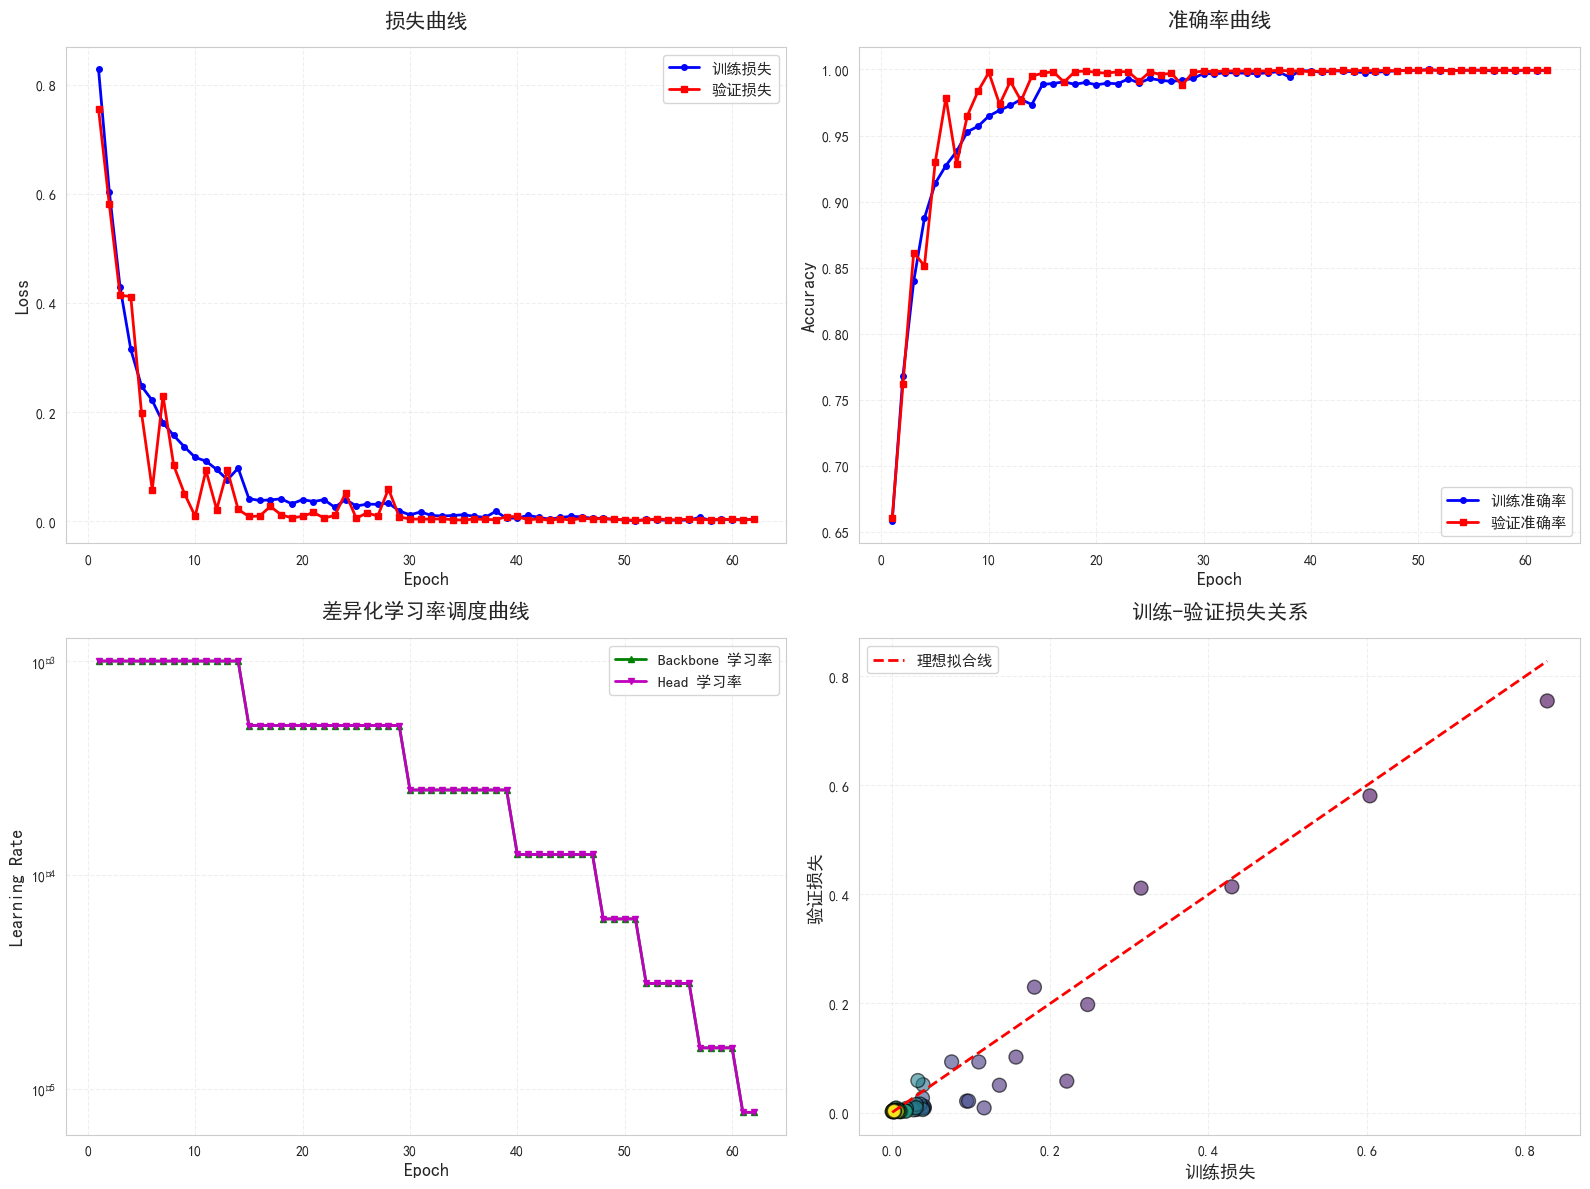

训练曲线已保存至: D:\WorkSpace2\plants-intelligent-system\train\runs\grape_disease_training_curves.png


In [7]:
# 绘制训练历史曲线
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

epochs_range = range(1, len(history['train_loss']) + 1)

# 损失曲线
axes[0, 0].plot(epochs_range, history['train_loss'], 'b-o', label='训练损失', linewidth=2, markersize=4)
axes[0, 0].plot(epochs_range, history['val_loss'], 'r-s', label='验证损失', linewidth=2, markersize=4)
axes[0, 0].set_xlabel('Epoch', fontsize=13)
axes[0, 0].set_ylabel('Loss', fontsize=13)
axes[0, 0].set_title('损失曲线', fontsize=15, fontweight='bold', pad=15)
axes[0, 0].legend(fontsize=11, loc='best')
axes[0, 0].grid(True, alpha=0.3, linestyle='--')

# 准确率曲线
axes[0, 1].plot(epochs_range, history['train_acc'], 'b-o', label='训练准确率', linewidth=2, markersize=4)
axes[0, 1].plot(epochs_range, history['val_acc'], 'r-s', label='验证准确率', linewidth=2, markersize=4)
axes[0, 1].set_xlabel('Epoch', fontsize=13)
axes[0, 1].set_ylabel('Accuracy', fontsize=13)
axes[0, 1].set_title('准确率曲线', fontsize=15, fontweight='bold', pad=15)
axes[0, 1].legend(fontsize=11, loc='best')
axes[0, 1].grid(True, alpha=0.3, linestyle='--')

# 🔧 方案1: 双学习率调度曲线
axes[1, 0].plot(epochs_range, history['lr_backbone'], 'g-^', label='Backbone 学习率', linewidth=2, markersize=5)
axes[1, 0].plot(epochs_range, history['lr_head'], 'm-v', label='Head 学习率', linewidth=2, markersize=5)
axes[1, 0].set_xlabel('Epoch', fontsize=13)
axes[1, 0].set_ylabel('Learning Rate', fontsize=13)
axes[1, 0].set_title('差异化学习率调度曲线', fontsize=15, fontweight='bold', pad=15)
axes[1, 0].set_yscale('log')
axes[1, 0].legend(fontsize=11)
axes[1, 0].grid(True, alpha=0.3, linestyle='--')
if UNFREEZE_EPOCH and UNFREEZE_EPOCH <= len(epochs_range):
    axes[1, 0].axvline(x=UNFREEZE_EPOCH, color='red', linestyle='--', linewidth=1.5, alpha=0.7, label='解冻点')

# 训练/验证损失对比
axes[1, 1].scatter(history['train_loss'], history['val_loss'], c=range(len(history['train_loss'])),
                   cmap='viridis', s=100, alpha=0.6, edgecolors='black')
axes[1, 1].plot([min(history['train_loss']), max(history['train_loss'])],
                [min(history['train_loss']), max(history['train_loss'])],
                'r--', linewidth=2, label='理想拟合线')
axes[1, 1].set_xlabel('训练损失', fontsize=13)
axes[1, 1].set_ylabel('验证损失', fontsize=13)
axes[1, 1].set_title('训练-验证损失关系', fontsize=15, fontweight='bold', pad=15)
axes[1, 1].legend(fontsize=11)
axes[1, 1].grid(True, alpha=0.3, linestyle='--')

plt.tight_layout()
curve_path = RUNS_DIR / 'grape_disease_training_curves.png'
plt.savefig(curve_path, dpi=150, bbox_inches='tight')
plt.show()
print(f'训练曲线已保存至: {curve_path}')

## 7. 测试集最终评估

final test:   0%|          | 0/28 [00:00<?, ?it/s]

Test accuracy: 0.9989
              precision    recall  f1-score   support

   Black Rot     0.9957    1.0000    0.9979       234
        ESCA     1.0000    1.0000    1.0000       246
     Healthy     1.0000    1.0000    1.0000       176
 Leaf Blight     1.0000    0.9957    0.9978       231

    accuracy                         0.9989       887
   macro avg     0.9989    0.9989    0.9989       887
weighted avg     0.9989    0.9989    0.9989       887


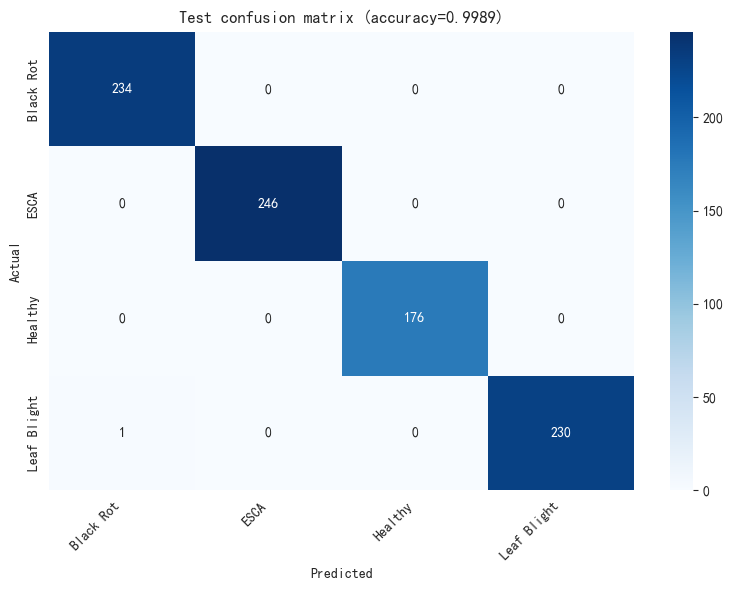

Test metrics saved to: D:\WorkSpace2\plants-intelligent-system\train\runs\grape_disease_metrics.json
Confusion matrix saved to: D:\WorkSpace2\plants-intelligent-system\train\runs\grape_disease_confusion_matrix.png


In [8]:
# The test set is used once, after selecting the checkpoint with validation loss.
model.eval()
y_true, y_pred = [], []
with torch.inference_mode():
    for inputs, labels in tqdm(loaders['test'], desc='final test'):
        logits = model(inputs.to(DEVICE, non_blocking=True))
        y_pred.extend(logits.argmax(1).cpu().tolist())
        y_true.extend(labels.tolist())

test_accuracy = float(np.mean(np.asarray(y_true) == np.asarray(y_pred)))
label_ids = list(range(len(class_names)))
cm = confusion_matrix(y_true, y_pred, labels=label_ids)
print(f'Test accuracy: {test_accuracy:.4f}')
print(classification_report(y_true, y_pred, labels=label_ids, target_names=class_names, zero_division=0, digits=4))
plt.figure(figsize=(max(8, len(class_names)), max(6, len(class_names) * 0.75)))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names)
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title(f'Test confusion matrix (accuracy={test_accuracy:.4f})')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
confusion_path = RUNS_DIR / 'grape_disease_confusion_matrix.png'
plt.savefig(confusion_path, dpi=150, bbox_inches='tight')
plt.show()

metrics_path = RUNS_DIR / 'grape_disease_metrics.json'
with metrics_path.open('w', encoding='utf-8') as f:
    json.dump({'test_accuracy': test_accuracy, 'best_val_loss': best_val_loss,
               'class_to_idx': class_to_idx}, f, ensure_ascii=False, indent=2)
print(f'Test metrics saved to: {metrics_path}')
print(f'Confusion matrix saved to: {confusion_path}')